In [3]:
%pip install pandas numpy matplotlib openpyxl statsmodels

In [6]:
import pandas as pd

excel_file = "base_datos_tfg_bitcoin.xlsx"

df = pd.read_excel(
    excel_file,
    sheet_name="Dataset_final",
    engine="openpyxl"
)

df.head()

,fecha,btc_usd,btc_return,sp500,sp500_return,gold_usd,gold_return,fed_funds_rate,fed_funds_change,cpi_index,inflation_yoy,m2_money_stock,m2_growth_yoy,halving_window_3m,btc_volatility_3m
0,2016-01-01,368.77,NaN,1940.24,NaN,1116.4,NaN,0.34,NaN,237.652,NaN,12518.5,NaN,0,NaN
1,2016-02-01,437.70,0.171361,1932.23,-0.004137,1233.9,0.100071,0.38,0.04,237.336,NaN,12603.9,NaN,0,NaN
2,2016-03-01,416.73,-0.049095,2059.74,0.063905,1234.2,0.000243,0.36,-0.02,238.080,NaN,12661.8,NaN,0,0.155886
3,2016-04-01,448.32,0.073069,2065.30,0.002696,1289.2,0.043599,0.37,0.01,238.992,NaN,12743.2,NaN,0,0.110443
4,2016-05-01,531.39,0.169989,2096.95,0.015208,1214.8,-0.059442,0.37,0.00,239.557,NaN,12802.0,NaN,0,0.109784


In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

os.makedirs("tablas", exist_ok=True)
os.makedirs("graficos", exist_ok=True)

# Por si la columna sigue llamándose fecha en vez de date
if "fecha" in df.columns and "date" not in df.columns:
    df = df.rename(columns={"fecha": "date"})

df["date"] = pd.to_datetime(df["date"])

# Cierre muestral:febrero de 2026
df = df[df["date"] <= "2026-02-01"].copy()

df = df.sort_values("date").reset_index(drop=True)

print("Base preparada correctamente")
print("Observaciones:", len(df))
print("Periodo:", df["date"].min().date(), "-", df["date"].max().date())

df.head()


Base preparada correctamente
Observaciones: 122
Periodo: 2016-01-01 - 2026-02-01


,date,btc_usd,btc_return,sp500,sp500_return,gold_usd,gold_return,fed_funds_rate,fed_funds_change,cpi_index,inflation_yoy,m2_money_stock,m2_growth_yoy,halving_window_3m,btc_volatility_3m
0,2016-01-01,368.77,NaN,1940.24,NaN,1116.4,NaN,0.34,NaN,237.652,NaN,12518.5,NaN,0,NaN
1,2016-02-01,437.70,0.171361,1932.23,-0.004137,1233.9,0.100071,0.38,0.04,237.336,NaN,12603.9,NaN,0,NaN
2,2016-03-01,416.73,-0.049095,2059.74,0.063905,1234.2,0.000243,0.36,-0.02,238.080,NaN,12661.8,NaN,0,0.155886
3,2016-04-01,448.32,0.073069,2065.30,0.002696,1289.2,0.043599,0.37,0.01,238.992,NaN,12743.2,NaN,0,0.110443
4,2016-05-01,531.39,0.169989,2096.95,0.015208,1214.8,-0.059442,0.37,0.00,239.557,NaN,12802.0,NaN,0,0.109784


In [8]:

variables_descriptivas = [
    "btc_usd",
    "btc_return",
    "sp500",
    "sp500_return",
    "gold_usd",
    "gold_return",
    "fed_funds_rate",
    "fed_funds_change",
    "cpi_index",
    "inflation_yoy",
    "m2_money_stock",
    "m2_growth_yoy",
    "halving_window_3m",
    "btc_volatility_3m"
]

descriptivos = df[variables_descriptivas].describe().T

# Nos quedamos solo con media, desviación típica, mínimo y máximo
descriptivos = descriptivos[["mean", "std", "min", "max"]]

descriptivos.columns = [
    "Media",
    "Desv. típica",
    "Mínimo",
    "Máximo"
]

# Redondear a 2 decimales
descriptivos = descriptivos.round(2)

# Guardar tabla
descriptivos.to_excel("tablas/estadisticos_descriptivos.xlsx")

descriptivos

,Media,Desv. típica,Mínimo,Máximo
btc_usd,31125.89,32123.05,368.77,115758.20
btc_return,0.04,0.20,-0.47,0.53
sp500,3839.15,1359.31,1932.23,6939.03
sp500_return,0.01,0.04,-0.13,0.12
gold_usd,1889.60,783.75,1116.40,5230.50
gold_return,0.01,0.04,-0.08,0.10
fed_funds_rate,2.21,1.91,0.05,5.33
fed_funds_change,0.03,0.19,-0.93,0.70
cpi_index,276.34,29.51,237.34,327.46
inflation_yoy,0.03,0.02,0.00,0.09


In [10]:
valores_ausentes = df.isna().sum().reset_index()
valores_ausentes.columns = ["Variable", "Valores ausentes"]
valores_ausentes = valores_ausentes[valores_ausentes["Variable"] != "date"]

valores_ausentes.to_excel("tablas/valores_ausentes.xlsx", index=False)

valores_ausentes

,Variable,Valores ausentes
1,btc_usd,0
2,btc_return,1
3,sp500,0
4,sp500_return,1
5,gold_usd,0
6,gold_return,1
7,fed_funds_rate,0
8,fed_funds_change,1
9,cpi_index,0
10,inflation_yoy,12


In [9]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd

variables_adf = [
    "btc_usd",
    "btc_return",
    "sp500",
    "sp500_return",
    "gold_usd",
    "gold_return",
    "fed_funds_rate",
    "fed_funds_change",
    "cpi_index",
    "inflation_yoy",
    "m2_money_stock",
    "m2_growth_yoy",
    "btc_volatility_3m"
]

resultados_adf = []

for variable in variables_adf:
    serie = df[variable].dropna()

    if len(serie) > 10:
        resultado = adfuller(serie, autolag="AIC")

        estadistico_adf = resultado[0]
        p_value = resultado[1]
        rezagos = resultado[2]
        observaciones = resultado[3]

        if p_value < 0.05:
            conclusion = "Estacionaria"
        else:
            conclusion = "No estacionaria"

        resultados_adf.append({
            "Variable": variable,
            "Estadístico ADF": estadistico_adf,
            "p-value": p_value,
            "Rezagos": rezagos,
            "Observaciones utilizadas": observaciones,
            "Conclusión": conclusion
        })

adf_table = pd.DataFrame(resultados_adf)

# Redondear para que quede limpio en la memoria
adf_table["Estadístico ADF"] = adf_table["Estadístico ADF"].round(4)
adf_table["p-value"] = adf_table["p-value"].round(4)

# Guardar tabla
adf_table.to_excel("tablas/dickey_fuller.xlsx", index=False)

adf_table

,Variable,Estadístico ADF,p-value,Rezagos,Observaciones utilizadas,Conclusión
0,btc_usd,-1.5383,0.5145,12,109,No estacionaria
1,btc_return,-9.3570,0.0000,0,120,Estacionaria
2,sp500,0.5105,0.9852,0,121,No estacionaria
3,sp500_return,-12.5008,0.0000,0,120,Estacionaria
4,gold_usd,7.3719,1.0000,0,121,No estacionaria
5,gold_return,-9.8640,0.0000,0,120,Estacionaria
6,fed_funds_rate,-1.7818,0.3895,3,118,No estacionaria
7,fed_funds_change,-2.9326,0.0417,2,118,Estacionaria
8,cpi_index,-0.1460,0.9447,7,114,No estacionaria
9,inflation_yoy,-1.7042,0.4290,13,96,No estacionaria


In [11]:
from google.colab import files

files.download("tablas/dickey_fuller.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

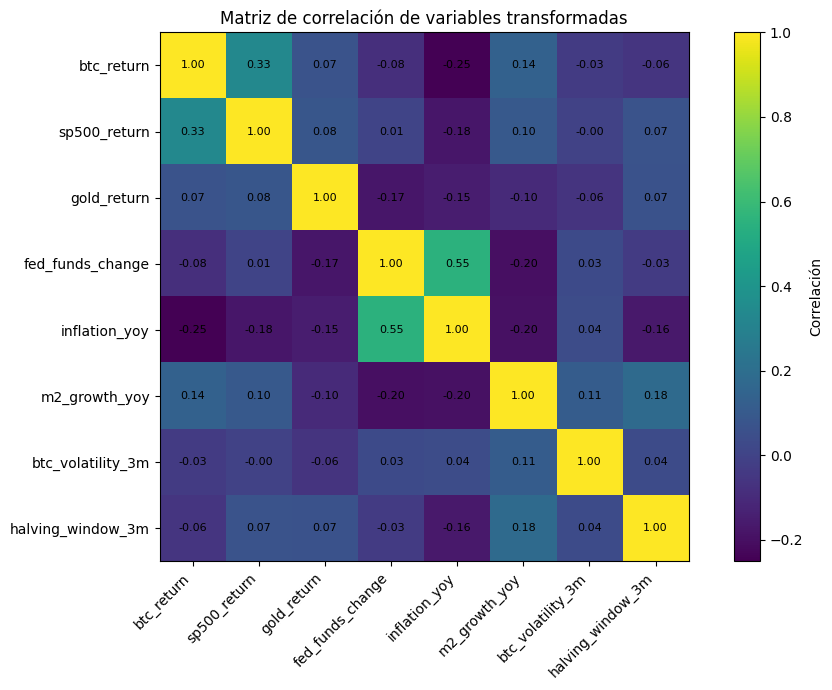

In [12]:
variables_correlacion = [
    "btc_return",
    "sp500_return",
    "gold_return",
    "fed_funds_change",
    "inflation_yoy",
    "m2_growth_yoy",
    "btc_volatility_3m",
    "halving_window_3m"
]

corr = df[variables_correlacion].corr()
corr.to_excel("tablas/matriz_correlacion.xlsx")

plt.figure(figsize=(10, 7))
plt.imshow(corr)
plt.colorbar(label="Correlación")

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr.index)),
    corr.index
)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title("Matriz de correlación de variables transformadas")
plt.tight_layout()
plt.savefig("graficos/matriz_correlacion.png", dpi=300, bbox_inches="tight")
plt.show()

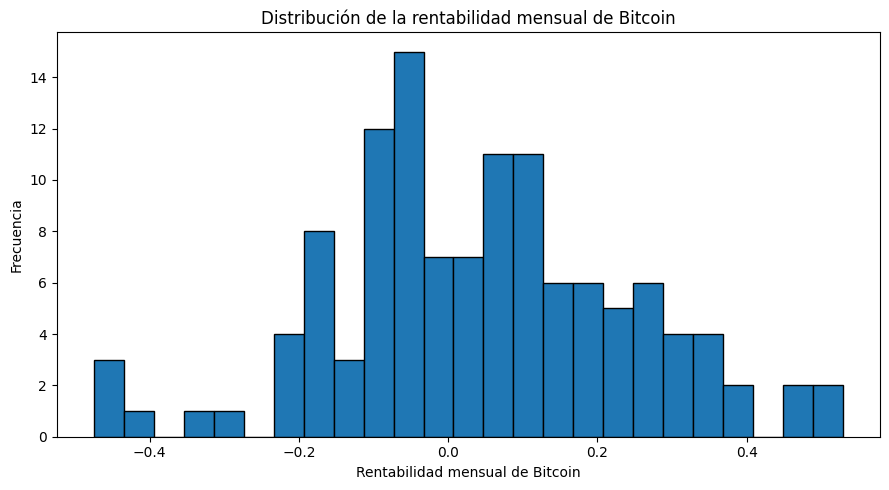

In [13]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["btc_return"].dropna(),
    bins=25,
    edgecolor="black"
)

plt.title("Distribución de la rentabilidad mensual de Bitcoin")
plt.xlabel("Rentabilidad mensual de Bitcoin")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.savefig("graficos/histograma_btc_return.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_1612/3838913652.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


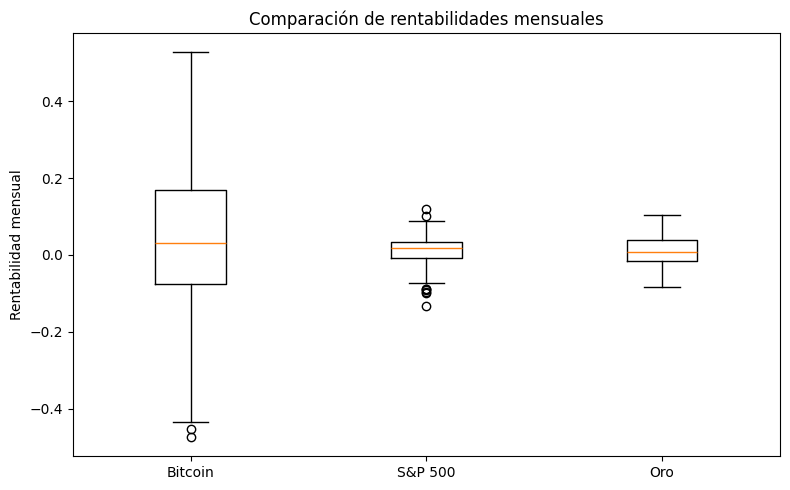

In [14]:
rentabilidades = df[[
    "btc_return",
    "sp500_return",
    "gold_return"
]].dropna()

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        rentabilidades["btc_return"],
        rentabilidades["sp500_return"],
        rentabilidades["gold_return"]
    ],
    labels=["Bitcoin", "S&P 500", "Oro"]
)

plt.title("Comparación de rentabilidades mensuales")
plt.ylabel("Rentabilidad mensual")

plt.tight_layout()
plt.savefig("graficos/boxplot_rentabilidades.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
# ANÁLISIS DEL DATO
# Modelos predictivos para la rentabilidad mensual de Bitcoin
# ============================================================

import os
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 0. CONFIGURACIÓN GENERAL
# ============================================================

print("ANÁLISIS DEL DATO")
print("Modelos: Regresión lineal múltiple y Random Forest Regressor")

# Carpeta donde se guardarán tablas y gráficos
output_dir = "outputs_analisis_dato"
os.makedirs(output_dir, exist_ok=True)

# Muestra cerrada en febrero de 2026
FECHA_FIN_MUESTRA = "2026-02-28"

# Usamos las variables explicativas del mes anterior para explicar/predecir la rentabilidad actual.
# Esto evita usar información del mismo mes que no estaría disponible al inicio del periodo.
LAG_FEATURES = True

# En principio lo dejamos en False para que el análisis se centre en determinantes externos.
# Si se quisiera un modelo más puramente predictivo, se podrían incluir rezagos de la propia rentabilidad.
INCLUDE_TARGET_LAGS = False

ANÁLISIS DEL DATO
Modelos: Regresión lineal múltiple y Random Forest Regressor


5. ANÁLISIS DEL DATO
Modelos: Regresión lineal múltiple y Random Forest Regressor

Dataframes candidatos encontrados:
- df | shape=(122, 15) | score=15

Dataframe seleccionado automáticamente: df

Columna temporal: date
Variable objetivo: btc_return
Rango temporal: 2016-01-01 00:00:00 -> 2026-02-01 00:00:00
Dimensión de la base seleccionada: (122, 15)

Columnas eliminadas por posible fuga de información:
[]

Número inicial de variables explicativas: 13

Dimensión final para modelado: (121, 15)
Número final de variables explicativas: 13

Periodo de entrenamiento:
2016-02-01 00:00:00 -> 2024-02-01 00:00:00 | Observaciones: 97

Periodo de prueba:
2024-03-01 00:00:00 -> 2026-02-01 00:00:00 | Observaciones: 24

Tabla de métricas de evaluación:


,Modelo,MAE,RMSE,MAPE_%,R2
0,Regresión lineal múltiple,0.533871,0.566056,860.293916,-20.438769
1,Random Forest Regressor,0.099942,0.121598,104.115143,0.010681



Primeras predicciones del periodo de prueba:


,Fecha,Real,Prediccion_Regresion_Lineal,Prediccion_Random_Forest,Error_Regresion_Lineal,Error_Random_Forest
0,2024-03-01,0.153247,-0.133491,-0.035741,0.286738,0.188989
1,2024-04-01,-0.162465,-0.378066,-0.049977,0.215601,-0.112488
2,2024-05-01,0.107071,-0.358668,-0.014902,0.465739,0.121973
3,2024-06-01,-0.073959,-0.380142,-0.043189,0.306184,-0.030769
4,2024-07-01,0.030497,-0.339808,-0.031242,0.370305,0.061739



Principales coeficientes del modelo lineal:


,Variable,Coeficiente_estandarizado,Abs_coeficiente
9,m2_money_stock,0.365792,0.365792
8,inflation_yoy,-0.179799,0.179799
10,m2_growth_yoy,-0.104141,0.104141
1,sp500,-0.090206,0.090206
5,fed_funds_rate,-0.088709,0.088709
0,btc_usd,-0.073927,0.073927
3,gold_usd,-0.064871,0.064871
4,gold_return,-0.045702,0.045702
7,cpi_index,-0.024487,0.024487
11,halving_window_3m,-0.020958,0.020958



Variables más importantes según Random Forest:


,Variable,Importancia
4,gold_return,0.183361
8,inflation_yoy,0.151785
0,btc_usd,0.107837
2,sp500_return,0.090809
12,btc_volatility_3m,0.081618
5,fed_funds_rate,0.068957
1,sp500,0.066471
3,gold_usd,0.063237
6,fed_funds_change,0.052184
7,cpi_index,0.048708


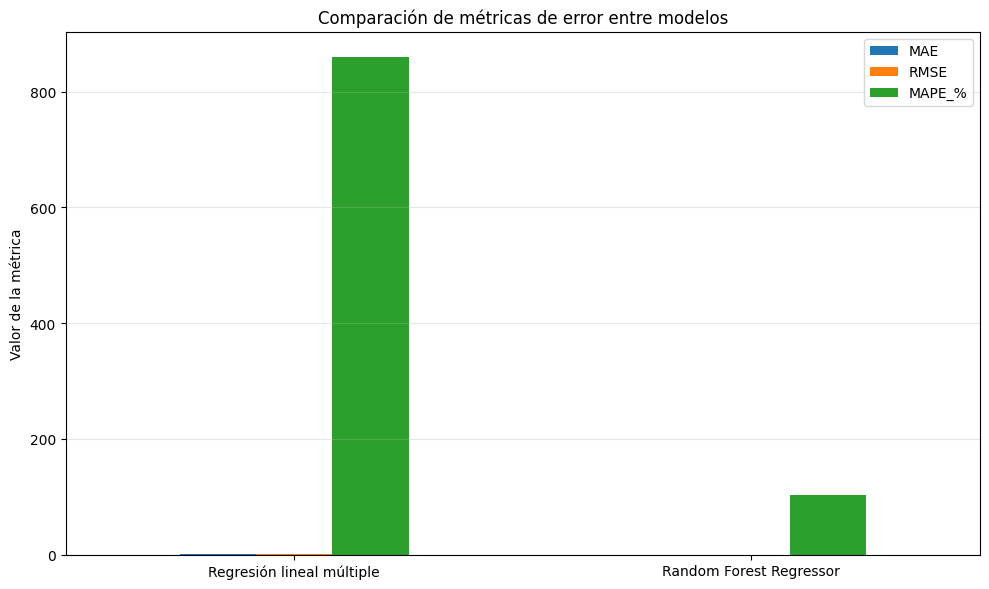

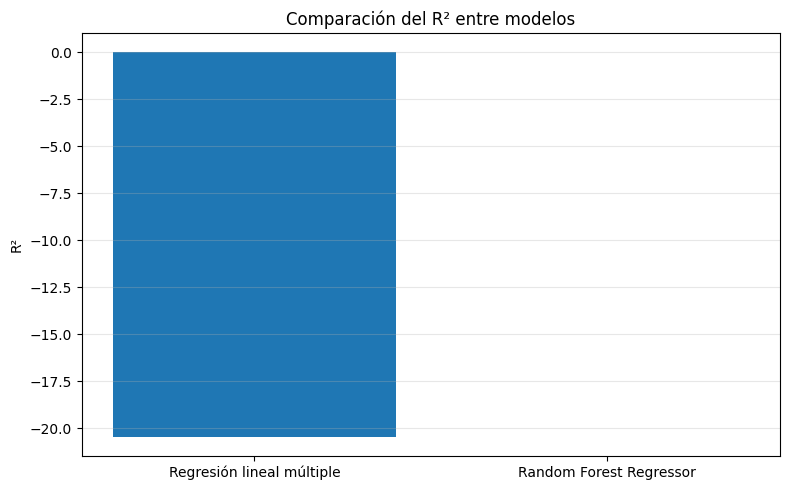

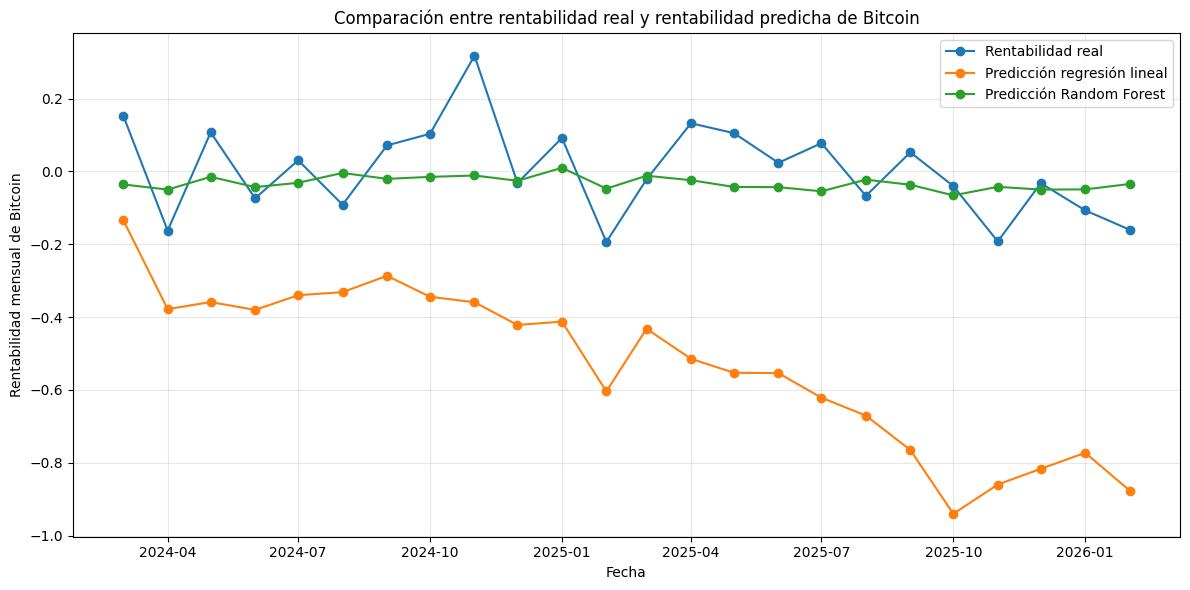

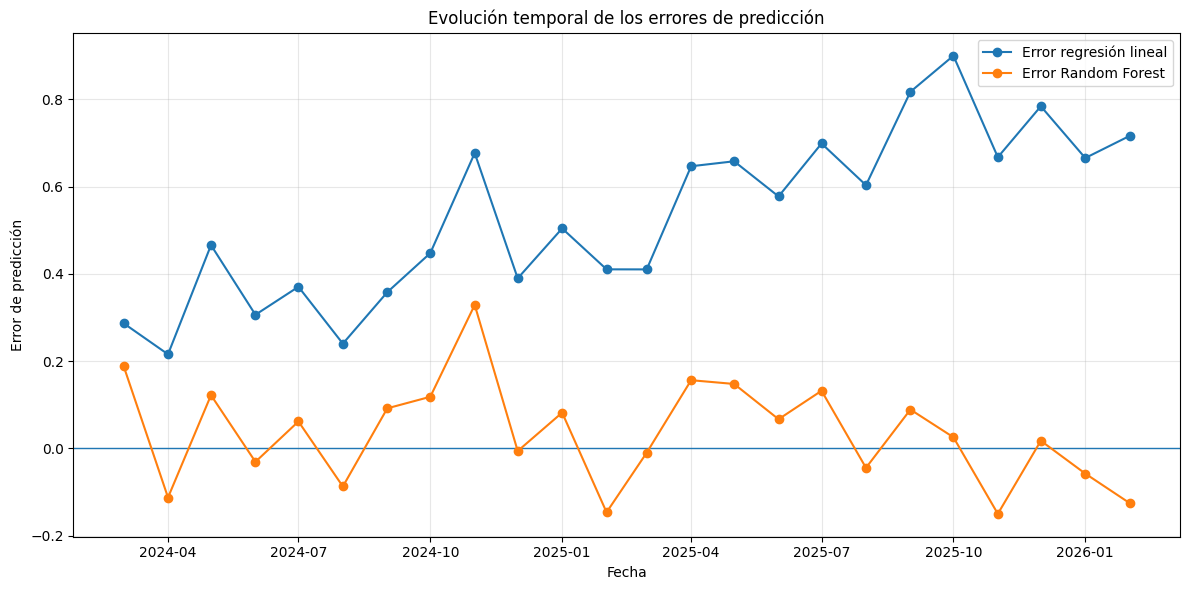

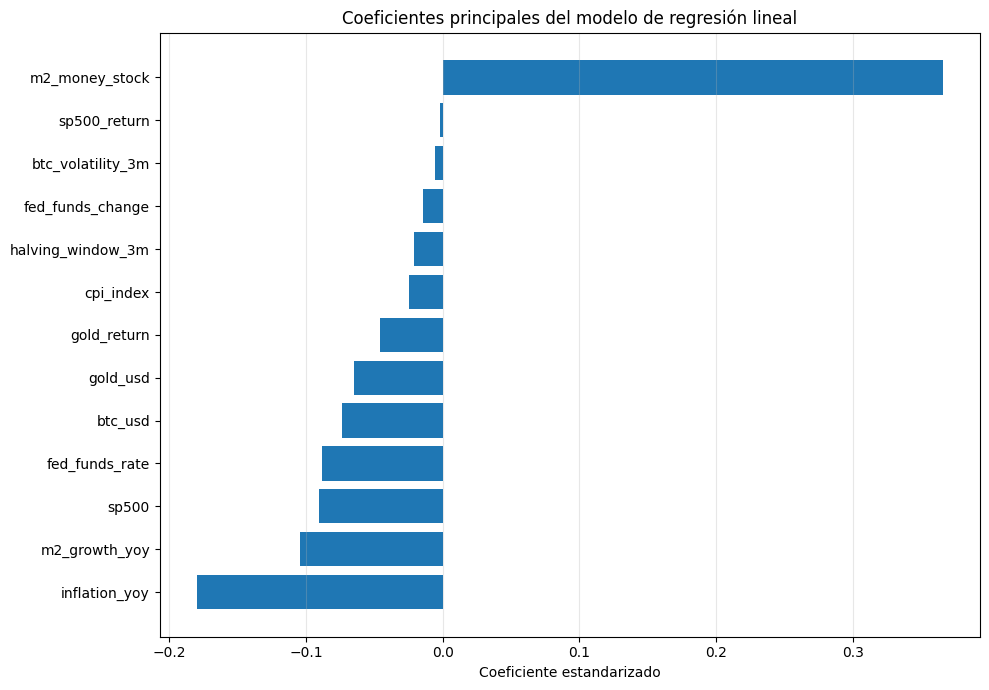

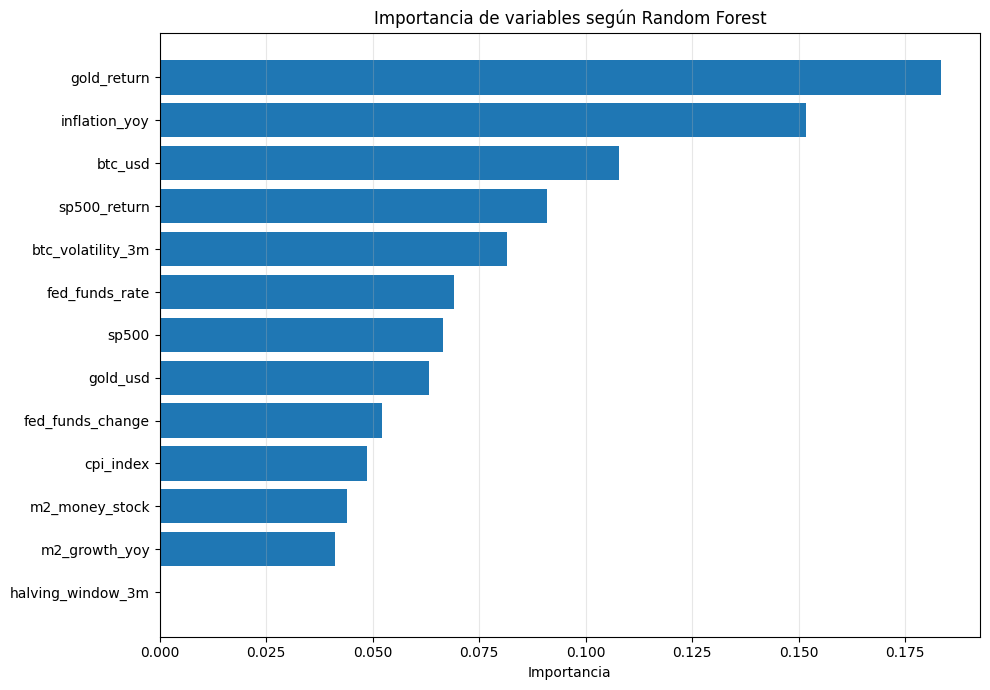


Proceso completado correctamente.
Tablas y gráficos guardados en la carpeta: outputs_analisis_dato

Archivos generados:
- 04_errores_en_el_tiempo.png
- predicciones_modelos.csv
- 02_comparacion_r2.png
- 01_comparacion_metricas_error.png
- tabla_metricas_modelos.csv
- coeficientes_regresion_lineal.csv
- 06_importancia_variables_random_forest.png
- 05_coeficientes_regresion_lineal.png
- 03_real_vs_predicciones.png
- importancia_variables_random_forest.csv


In [16]:
# ============================================================
# 5. ANÁLISIS DEL DATO
# Modelos predictivos para la rentabilidad mensual de Bitcoin
# ============================================================

import os
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 0. CONFIGURACIÓN GENERAL
# ============================================================

print("5. ANÁLISIS DEL DATO")
print("Modelos: Regresión lineal múltiple y Random Forest Regressor")

# Carpeta donde se guardarán tablas y gráficos
output_dir = "outputs_analisis_dato"
os.makedirs(output_dir, exist_ok=True)

# Muestra cerrada en febrero de 2026
FECHA_FIN_MUESTRA = "2026-02-28"

# Usamos las variables explicativas del mes anterior para explicar/predecir la rentabilidad actual.
# Esto evita usar información del mismo mes que no estaría disponible al inicio del periodo.
LAG_FEATURES = True

# En principio lo dejamos en False para que el análisis se centre en determinantes externos.
# Si se quisiera un modelo más puramente predictivo, se podrían incluir rezagos de la propia rentabilidad.
INCLUDE_TARGET_LAGS = False


# ============================================================
# 1. FUNCIONES AUXILIARES
# ============================================================

def limpiar_texto(texto):
    """
    Normaliza texto para detectar columnas aunque tengan tildes, mayúsculas o nombres diferentes.
    """
    texto = str(texto).lower()
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("utf-8")
    return texto


def detectar_columna_fecha(df):
    """
    Detecta la columna temporal. Si el índice ya es fecha, lo convierte en columna.
    """
    df = df.copy()

    if isinstance(df.index, pd.DatetimeIndex):
        df["Fecha"] = df.index
        return df, "Fecha"

    posibles = ["fecha", "date", "mes", "month", "periodo", "time"]

    for col in df.columns:
        col_limpia = limpiar_texto(col)
        if any(p in col_limpia for p in posibles):
            return df, col

    raise ValueError("No se ha detectado columna de fecha. Revisa si la base tiene una columna temporal.")


def detectar_dataframe_final():
    """
    Busca automáticamente el dataframe final creado en Ingeniería del dato.
    Prioriza dataframes mensuales, con columnas de Bitcoin, suficientes variables y no excesivamente grandes.
    """
    candidatos = []

    nombres_a_evitar = {
        "metrics_df", "predictions_df", "coef_df", "importance_df",
        "X", "y", "X_train", "X_test", "y_train", "y_test",
        "model_data"
    }

    for nombre, objeto in globals().items():

        if nombre in nombres_a_evitar:
            continue

        if isinstance(objeto, pd.DataFrame):

            columnas_texto = " ".join([limpiar_texto(c) for c in objeto.columns])

            tiene_btc = ("btc" in columnas_texto) or ("bitcoin" in columnas_texto)
            tiene_filas = objeto.shape[0] >= 24
            tiene_columnas = objeto.shape[1] >= 5

            if tiene_btc and tiene_filas and tiene_columnas:

                score = 0
                nombre_limpio = limpiar_texto(nombre)

                # Preferencias razonables para escoger el dataframe final
                if "mensual" in nombre_limpio or "monthly" in nombre_limpio:
                    score += 50
                if "final" in nombre_limpio:
                    score += 40
                if "model" in nombre_limpio or "modelo" in nombre_limpio:
                    score += 30
                if "transform" in nombre_limpio or "transformed" in nombre_limpio:
                    score += 20
                if "limpio" in nombre_limpio or "clean" in nombre_limpio:
                    score += 20

                # Penalizamos bases demasiado grandes, que suelen ser diarias y no mensuales
                if objeto.shape[0] > 1000:
                    score -= 50

                # Premiamos que tenga más variables
                score += objeto.shape[1]

                candidatos.append((score, nombre, objeto.shape))

    if len(candidatos) == 0:
        raise ValueError(
            "No se ha encontrado automáticamente el dataframe final. "
            "Ejecuta antes las celdas de Ingeniería del dato."
        )

    candidatos = sorted(candidatos, reverse=True)

    print("\nDataframes candidatos encontrados:")
    for score, nombre, shape in candidatos[:5]:
        print(f"- {nombre} | shape={shape} | score={score}")

    mejor_nombre = candidatos[0][1]
    print("\nDataframe seleccionado automáticamente:", mejor_nombre)

    return globals()[mejor_nombre].copy()


def detectar_variable_objetivo(df):
    """
    Detecta la variable objetivo: rentabilidad mensual de Bitcoin.
    Si no existe, intenta crearla a partir de una columna de precio de Bitcoin.
    """
    patrones_rentabilidad = [
        "btc_return", "bitcoin_return", "return_btc", "return_bitcoin",
        "btc_returns", "bitcoin_returns", "returns_btc", "returns_bitcoin",
        "rentabilidad_btc", "rentabilidad_bitcoin",
        "rentabilidad_mensual_btc", "rentabilidad_mensual_bitcoin",
        "retorno_btc", "retorno_bitcoin",
        "rendimiento_btc", "rendimiento_bitcoin",
        "btc_ret", "bitcoin_ret",
        "btc_log_return", "bitcoin_log_return"
    ]

    for col in df.columns:
        col_limpia = limpiar_texto(col)
        if any(p in col_limpia for p in patrones_rentabilidad):
            return df, col

    patrones_precio = [
        "btc_price", "bitcoin_price",
        "precio_btc", "precio_bitcoin",
        "btc_close", "bitcoin_close",
        "close_btc", "close_bitcoin",
        "btc", "bitcoin"
    ]

    columnas_numericas = df.select_dtypes(include=[np.number]).columns.tolist()

    for col in columnas_numericas:
        col_limpia = limpiar_texto(col)
        if any(p in col_limpia for p in patrones_precio):
            df = df.copy()
            nueva_columna = "rentabilidad_mensual_btc"
            df[nueva_columna] = df[col].pct_change()
            print(f"\nNo se encontró rentabilidad ya creada. Se ha calculado '{nueva_columna}' desde '{col}'.")
            return df, nueva_columna

    raise ValueError(
        "No se ha detectado una columna de rentabilidad ni una columna de precio de Bitcoin."
    )


def mape_seguro(y_real, y_pred):
    """
    Calcula MAPE evitando divisiones por valores reales cercanos a cero.
    """
    y_real = np.array(y_real)
    y_pred = np.array(y_pred)

    mascara = np.abs(y_real) > 1e-8

    if mascara.sum() == 0:
        return np.nan

    return np.mean(np.abs((y_real[mascara] - y_pred[mascara]) / y_real[mascara])) * 100


def calcular_metricas(y_real, y_pred):
    """
    Calcula MAE, RMSE, MAPE y R².
    """
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mape = mape_seguro(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_%": mape,
        "R2": r2
    }


# ============================================================
# 2. DETECCIÓN Y PREPARACIÓN DEL DATAFRAME
# ============================================================

df_model = detectar_dataframe_final()

df_model, date_col = detectar_columna_fecha(df_model)
df_model[date_col] = pd.to_datetime(df_model[date_col], errors="coerce")

df_model = df_model.dropna(subset=[date_col])
df_model = df_model.sort_values(date_col).reset_index(drop=True)

# Cierre definitivo de la muestra
df_model = df_model[df_model[date_col] <= pd.to_datetime(FECHA_FIN_MUESTRA)].copy()

# Detección de variable objetivo
df_model, target_col = detectar_variable_objetivo(df_model)

print("\nColumna temporal:", date_col)
print("Variable objetivo:", target_col)
print("Rango temporal:", df_model[date_col].min(), "->", df_model[date_col].max())
print("Dimensión de la base seleccionada:", df_model.shape)


# ============================================================
# 3. SELECCIÓN DE VARIABLES EXPLICATIVAS
# ============================================================

# Se seleccionan solo variables numéricas
numeric_cols = df_model.select_dtypes(include=[np.number]).columns.tolist()

# Variables explicativas iniciales
feature_cols = [col for col in numeric_cols if col != target_col]

# Eliminamos posibles columnas que puedan generar fuga de información:
# por ejemplo, precio de Bitcoin del mismo mes o rentabilidad de Bitcoin duplicada.
patrones_leakage = [
    "btc_price", "bitcoin_price",
    "precio_btc", "precio_bitcoin",
    "btc_close", "bitcoin_close",
    "close_btc", "close_bitcoin",
    "btc_open", "bitcoin_open",
    "open_btc", "open_bitcoin",
    "rentabilidad_btc", "rentabilidad_bitcoin",
    "rentabilidad_mensual_btc", "rentabilidad_mensual_bitcoin",
    "btc_return", "bitcoin_return",
    "return_btc", "return_bitcoin",
    "retorno_btc", "retorno_bitcoin",
    "rendimiento_btc", "rendimiento_bitcoin"
]

columnas_eliminadas = []

for col in feature_cols.copy():
    col_limpia = limpiar_texto(col)
    if any(p in col_limpia for p in patrones_leakage):
        feature_cols.remove(col)
        columnas_eliminadas.append(col)

print("\nColumnas eliminadas por posible fuga de información:")
print(columnas_eliminadas)

print("\nNúmero inicial de variables explicativas:", len(feature_cols))


# ============================================================
# 4. CREACIÓN DEL DATASET FINAL DE MODELADO
# ============================================================

model_data = df_model[[date_col, target_col] + feature_cols].copy()

# Sustituimos infinitos por nulos
model_data = model_data.replace([np.inf, -np.inf], np.nan)

# Desplazamos las variables explicativas un mes
if LAG_FEATURES:
    model_data[feature_cols] = model_data[feature_cols].shift(1)

# Opcional: incluir rezagos de la propia rentabilidad de Bitcoin
if INCLUDE_TARGET_LAGS:
    model_data["btc_return_lag_1"] = model_data[target_col].shift(1)
    model_data["btc_return_lag_2"] = model_data[target_col].shift(2)
    feature_cols = feature_cols + ["btc_return_lag_1", "btc_return_lag_2"]

# Eliminamos filas sin variable objetivo
model_data = model_data.dropna(subset=[target_col]).copy()

# Eliminamos columnas completamente vacías
columnas_vacias = [col for col in feature_cols if model_data[col].isna().all()]
feature_cols = [col for col in feature_cols if col not in columnas_vacias]

if columnas_vacias:
    print("\nColumnas eliminadas por estar completamente vacías:")
    print(columnas_vacias)

# Dataset final
X = model_data[feature_cols]
y = model_data[target_col]
dates = model_data[date_col]

print("\nDimensión final para modelado:", model_data.shape)
print("Número final de variables explicativas:", len(feature_cols))


# ============================================================
# 5. DIVISIÓN TEMPORAL TRAIN / TEST
# ============================================================

n = len(model_data)

# Reservamos aproximadamente el 20% final para test, respetando el orden temporal
n_test = max(12, int(n * 0.20))

# Evitamos que el test sea excesivamente grande si la muestra no es muy amplia
n_test = min(n_test, int(n * 0.33))

train_end = n - n_test

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]

dates_train = dates.iloc[:train_end]
dates_test = dates.iloc[train_end:]

print("\nPeriodo de entrenamiento:")
print(dates_train.min(), "->", dates_train.max(), "| Observaciones:", len(X_train))

print("\nPeriodo de prueba:")
print(dates_test.min(), "->", dates_test.max(), "| Observaciones:", len(X_test))


# ============================================================
# 6. MODELO 1: REGRESIÓN LINEAL MÚLTIPLE
# ============================================================

linear_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)


# ============================================================
# 7. MODELO 2: RANDOM FOREST REGRESSOR
# ============================================================

rf_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=500,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)


# ============================================================
# 8. MÉTRICAS DE EVALUACIÓN
# ============================================================

metrics_linear = calcular_metricas(y_test, y_pred_linear)
metrics_rf = calcular_metricas(y_test, y_pred_rf)

metrics_df = pd.DataFrame([
    {"Modelo": "Regresión lineal múltiple", **metrics_linear},
    {"Modelo": "Random Forest Regressor", **metrics_rf}
])

print("\nTabla de métricas de evaluación:")
display(metrics_df)

metrics_df.to_csv(f"{output_dir}/tabla_metricas_modelos.csv", index=False)


# ============================================================
# 9. TABLA DE PREDICCIONES
# ============================================================

predictions_df = pd.DataFrame({
    "Fecha": dates_test.values,
    "Real": y_test.values,
    "Prediccion_Regresion_Lineal": y_pred_linear,
    "Prediccion_Random_Forest": y_pred_rf
})

predictions_df["Error_Regresion_Lineal"] = (
    predictions_df["Real"] - predictions_df["Prediccion_Regresion_Lineal"]
)

predictions_df["Error_Random_Forest"] = (
    predictions_df["Real"] - predictions_df["Prediccion_Random_Forest"]
)

print("\nPrimeras predicciones del periodo de prueba:")
display(predictions_df.head())

predictions_df.to_csv(f"{output_dir}/predicciones_modelos.csv", index=False)


# ============================================================
# 10. COEFICIENTES DE LA REGRESIÓN LINEAL
# ============================================================

coeficientes = linear_model.named_steps["model"].coef_

coef_df = pd.DataFrame({
    "Variable": feature_cols,
    "Coeficiente_estandarizado": coeficientes
})

coef_df["Abs_coeficiente"] = coef_df["Coeficiente_estandarizado"].abs()
coef_df = coef_df.sort_values("Abs_coeficiente", ascending=False)

print("\nPrincipales coeficientes del modelo lineal:")
display(coef_df.head(15))

coef_df.to_csv(f"{output_dir}/coeficientes_regresion_lineal.csv", index=False)


# ============================================================
# 11. IMPORTANCIA DE VARIABLES EN RANDOM FOREST
# ============================================================

importancias = rf_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Variable": feature_cols,
    "Importancia": importancias
})

importance_df = importance_df.sort_values("Importancia", ascending=False)

print("\nVariables más importantes según Random Forest:")
display(importance_df.head(15))

importance_df.to_csv(f"{output_dir}/importancia_variables_random_forest.csv", index=False)


# ============================================================
# 12. GRÁFICO 1: COMPARACIÓN DE MÉTRICAS DE ERROR
# ============================================================

metrics_plot = metrics_df.set_index("Modelo")[["MAE", "RMSE", "MAPE_%"]]

plt.figure(figsize=(10, 6))
metrics_plot.plot(kind="bar", ax=plt.gca())
plt.title("Comparación de métricas de error entre modelos")
plt.ylabel("Valor de la métrica")
plt.xlabel("")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{output_dir}/01_comparacion_metricas_error.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 13. GRÁFICO 2: COMPARACIÓN DEL R²
# ============================================================

plt.figure(figsize=(8, 5))
plt.bar(metrics_df["Modelo"], metrics_df["R2"])
plt.title("Comparación del R² entre modelos")
plt.ylabel("R²")
plt.xlabel("")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{output_dir}/02_comparacion_r2.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 14. GRÁFICO 3: RENTABILIDAD REAL VS PREDICCIONES
# ============================================================

plt.figure(figsize=(12, 6))
plt.plot(
    predictions_df["Fecha"],
    predictions_df["Real"],
    marker="o",
    label="Rentabilidad real"
)
plt.plot(
    predictions_df["Fecha"],
    predictions_df["Prediccion_Regresion_Lineal"],
    marker="o",
    label="Predicción regresión lineal"
)
plt.plot(
    predictions_df["Fecha"],
    predictions_df["Prediccion_Random_Forest"],
    marker="o",
    label="Predicción Random Forest"
)

plt.title("Comparación entre rentabilidad real y rentabilidad predicha de Bitcoin")
plt.xlabel("Fecha")
plt.ylabel("Rentabilidad mensual de Bitcoin")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{output_dir}/03_real_vs_predicciones.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 15. GRÁFICO 4: ERRORES EN EL TIEMPO
# ============================================================

plt.figure(figsize=(12, 6))
plt.axhline(0, linewidth=1)

plt.plot(
    predictions_df["Fecha"],
    predictions_df["Error_Regresion_Lineal"],
    marker="o",
    label="Error regresión lineal"
)
plt.plot(
    predictions_df["Fecha"],
    predictions_df["Error_Random_Forest"],
    marker="o",
    label="Error Random Forest"
)

plt.title("Evolución temporal de los errores de predicción")
plt.xlabel("Fecha")
plt.ylabel("Error de predicción")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{output_dir}/04_errores_en_el_tiempo.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 16. GRÁFICO 5: COEFICIENTES DE LA REGRESIÓN LINEAL
# ============================================================

top_coef = coef_df.head(15).sort_values("Coeficiente_estandarizado")

plt.figure(figsize=(10, 7))
plt.barh(top_coef["Variable"], top_coef["Coeficiente_estandarizado"])
plt.title("Coeficientes principales del modelo de regresión lineal")
plt.xlabel("Coeficiente estandarizado")
plt.ylabel("")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{output_dir}/05_coeficientes_regresion_lineal.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 17. GRÁFICO 6: IMPORTANCIA DE VARIABLES EN RANDOM FOREST
# ============================================================

top_importance = importance_df.head(15).sort_values("Importancia")

plt.figure(figsize=(10, 7))
plt.barh(top_importance["Variable"], top_importance["Importancia"])
plt.title("Importancia de variables según Random Forest")
plt.xlabel("Importancia")
plt.ylabel("")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{output_dir}/06_importancia_variables_random_forest.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 18. RESUMEN FINAL
# ============================================================

print("\nProceso completado correctamente.")
print(f"Tablas y gráficos guardados en la carpeta: {output_dir}")

print("\nArchivos generados:")
for archivo in os.listdir(output_dir):
    print("-", archivo)

5.4. ANÁLISIS MULTIFACTORIAL DE BITCOIN
Carpeta de resultados: outputs_analisis_dato/analisis_multifactorial

Variables detectadas:


,Concepto,Columna_detectada
0,Rentabilidad S&P 500,sp500_return
1,Rentabilidad del oro,gold_return
2,Inflación interanual,inflation_yoy
3,Crecimiento M2,m2_growth_yoy
4,Tipo de interés,fed_funds_rate
5,Cambio en tipos,fed_funds_change
6,Volatilidad Bitcoin,btc_volatility_3m
7,Ventana halving,halving_window_3m



Resumen de correlaciones móviles:


,Relación,Media,Mediana,Mínimo,Máximo
0,Corr_BTC_SP500_12m,0.280762,0.360513,-0.537407,0.757948
1,Corr_BTC_Oro_12m,0.149099,0.171036,-0.462751,0.753405


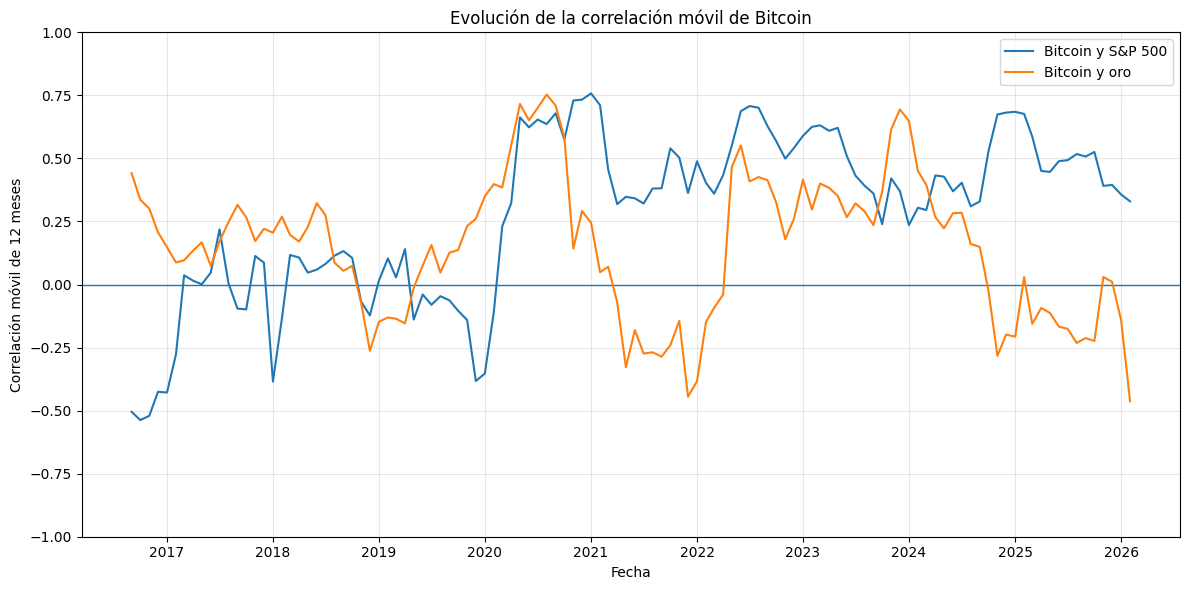


Correlaciones adelantadas y rezagadas:


,Lag_meses,Corr_BTC_SP500,Corr_BTC_Oro
0,-6,0.063005,-0.077437
1,-5,-0.026379,0.023646
2,-4,0.075712,0.040004
3,-3,0.094215,0.011424
4,-2,-0.027706,0.030905
5,-1,0.163360,-0.047034
6,0,0.331647,0.068658
7,1,-0.067449,-0.227326
8,2,0.024891,-0.074730
9,3,0.164412,0.135158


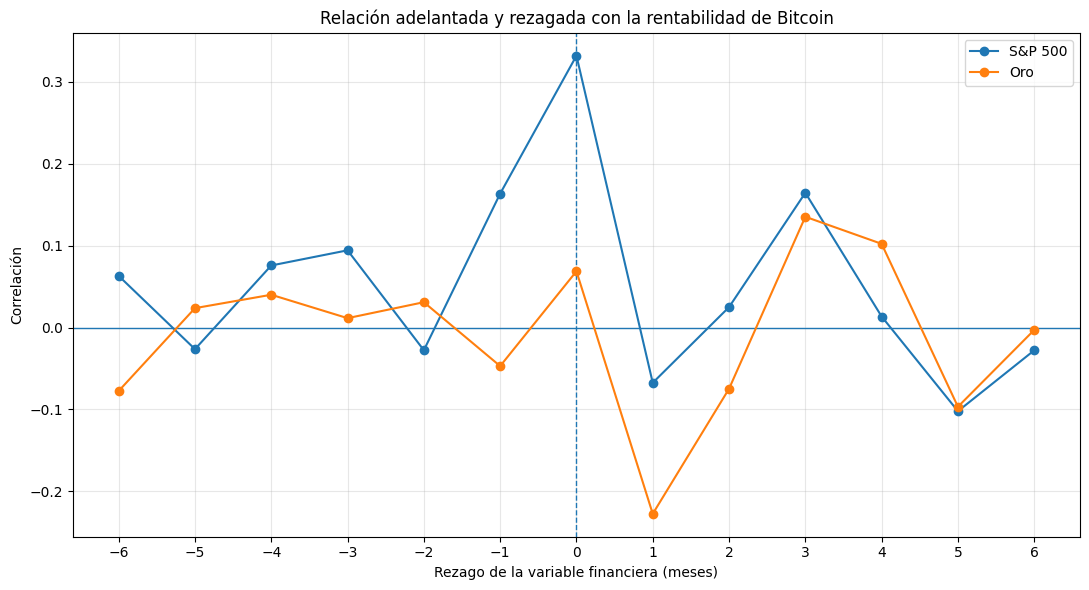


Bitcoin según régimen de inflación:


,Regimen_inflacion,Observaciones,Rentabilidad_media_%,Rentabilidad_mediana_%,Volatilidad_%,Meses_positivos_%
0,Inflación alta,55,-0.938419,-3.130680,16.635437,45.454545
1,Inflación baja,54,8.797793,9.592528,22.874239,62.962963


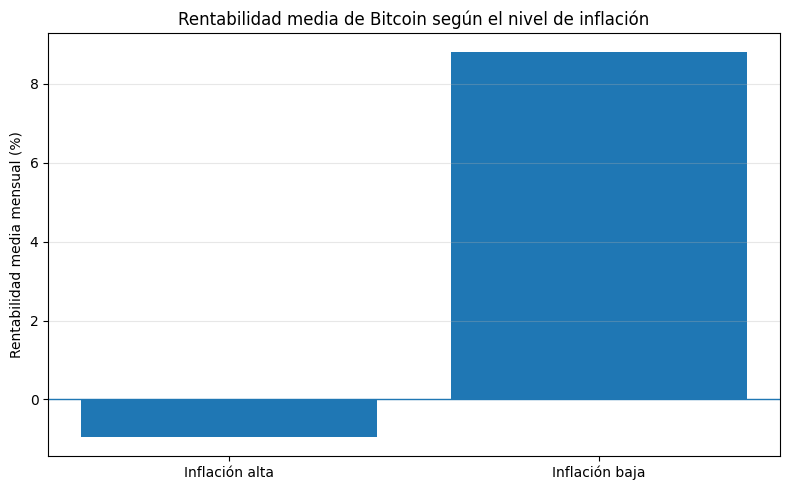

Prueba Mann-Whitney inflación: estadístico=1874.000, p-valor=0.0185

Bitcoin según régimen de liquidez:


,Regimen_M2,Observaciones,Rentabilidad_media_%,Rentabilidad_mediana_%,Volatilidad_%,Meses_positivos_%
0,Contracción de M2,15,9.740888,8.418751,14.335384,80.0
1,Expansión de M2,94,2.950579,-0.144231,21.196595,50.0


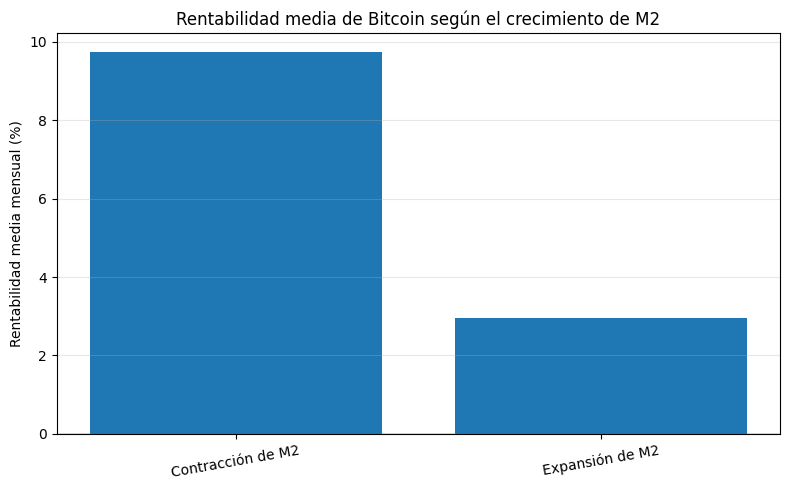

Prueba Mann-Whitney M2: estadístico=868.000, p-valor=0.1529

Bitcoin según movimiento de los tipos de interés:


,Regimen_tipos,Observaciones,Rentabilidad_media_%,Rentabilidad_mediana_%,Volatilidad_%,Meses_positivos_%
0,Bajada de tipos,26,4.512746,-2.592267,18.215607,46.153846
2,Tipos sin cambio,38,6.976324,6.715668,18.071796,68.421053
1,Subida de tipos,56,2.154527,0.361775,21.683856,51.785714


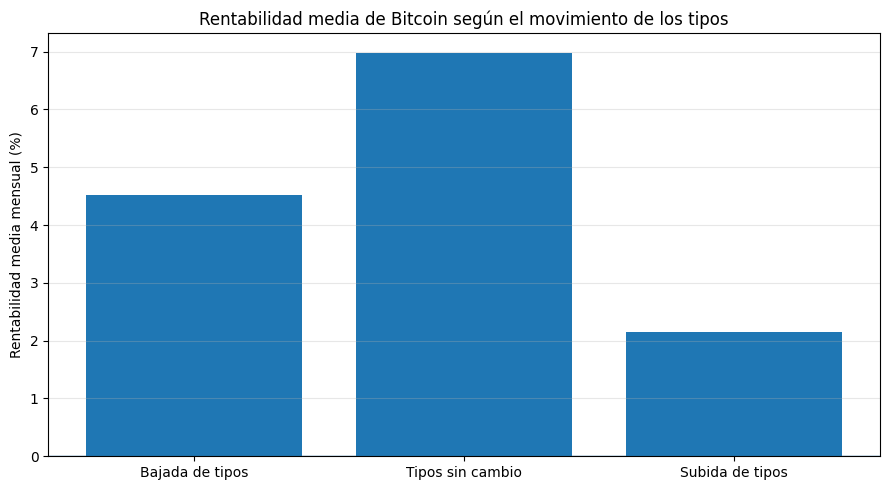

Prueba Kruskal-Wallis tipos: estadístico=1.744, p-valor=0.4182

Comportamiento de Bitcoin en torno a los halvings:


,Periodo_halving,Observaciones,Rentabilidad_media_%,Rentabilidad_mediana_%,Volatilidad_%,Meses_positivos_%
1,3 meses anteriores,9,10.292561,15.324745,20.264696,77.777778
0,0-3 meses posteriores,12,2.006332,3.078392,10.895691,58.333333
2,4-12 meses posteriores,27,10.927304,10.321341,20.229142,70.370370
3,Fuera de ventana,73,1.485960,-3.244162,20.260206,47.945205


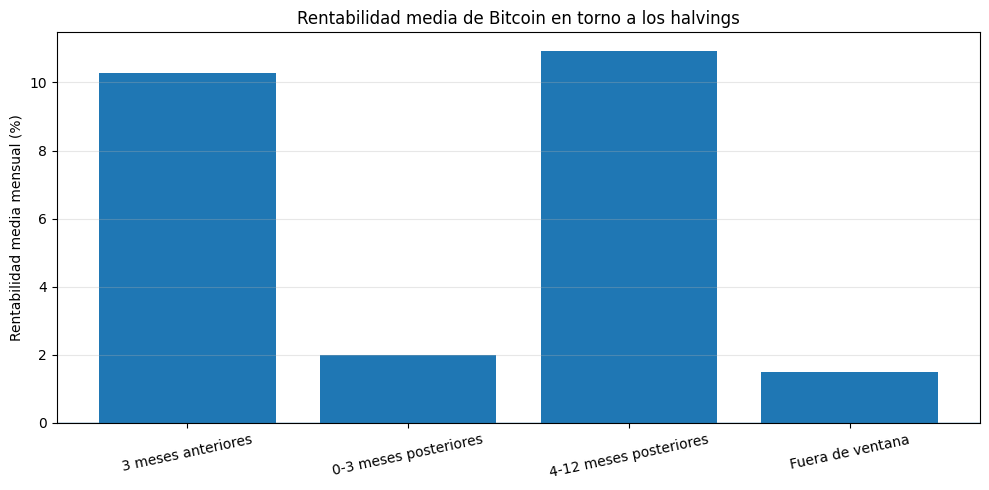

Prueba Kruskal-Wallis halvings: estadístico=6.724, p-valor=0.0812

Precisión direccional:


,Modelo,Precision_direccional_%
0,Baseline dirección mayoritaria,50.000000
1,Regresión lineal múltiple,50.000000
2,Random Forest Regressor,54.166667


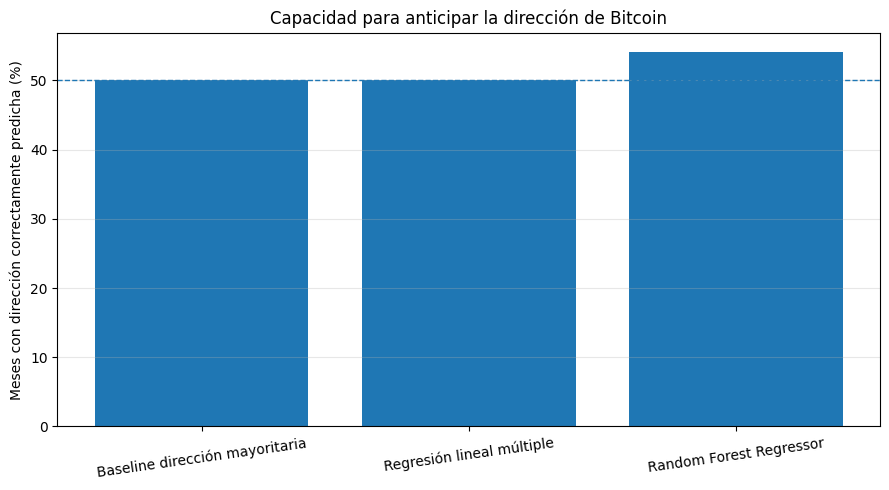


Validación temporal por ventanas:


,Ventana,Modelo,Fecha_inicio_test,Fecha_fin_test,MAE,RMSE,R2,Precision_direccional_%
0,1,Regresión lineal,2017-11-01,2019-06-01,2.520262,2.942243,-127.366056,45.0
1,1,Random Forest,2017-11-01,2019-06-01,0.272530,0.341101,-0.725280,50.0
2,2,Regresión lineal,2019-07-01,2021-02-01,1.214342,1.456519,-56.375231,55.0
3,2,Random Forest,2019-07-01,2021-02-01,0.158665,0.180202,0.121769,55.0
4,3,Regresión lineal,2021-03-01,2022-10-01,1.827294,1.958182,-90.142911,65.0
5,3,Random Forest,2021-03-01,2022-10-01,0.196698,0.249292,-0.477185,45.0
6,4,Regresión lineal,2022-11-01,2024-06-01,0.787908,0.876987,-33.673890,35.0
7,4,Random Forest,2022-11-01,2024-06-01,0.155393,0.194638,-0.707928,40.0
8,5,Regresión lineal,2024-07-01,2026-02-01,0.203527,0.233865,-2.746027,50.0
9,5,Random Forest,2024-07-01,2026-02-01,0.093052,0.114854,0.096498,60.0



Resumen de validación temporal:


,Modelo,MAE_medio,RMSE_medio,R2_medio,Precision_direccional_media
0,Random Forest,0.175267,0.216017,-0.338425,50.0
1,Regresión lineal,1.310667,1.493559,-62.060823,50.0


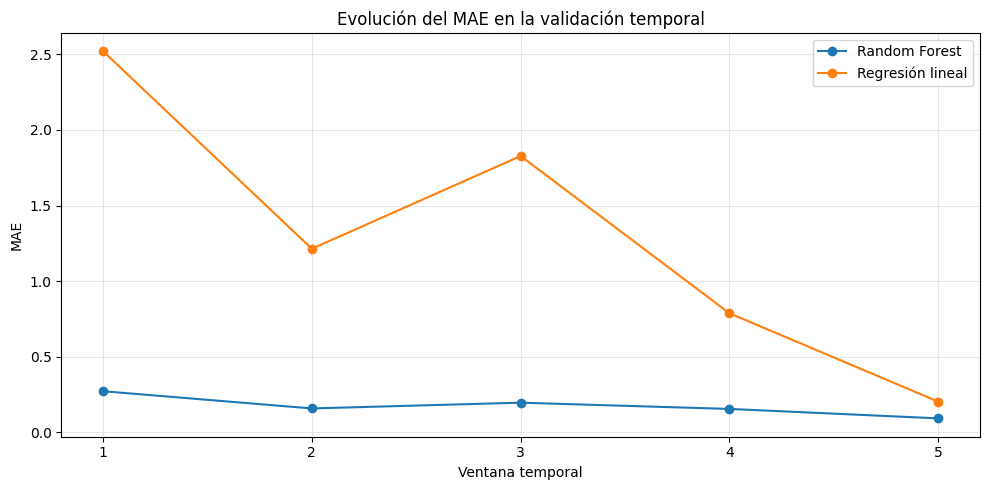


Variables seleccionadas para dependencia parcial:
['gold_return', 'inflation_yoy', 'btc_usd', 'sp500_return']


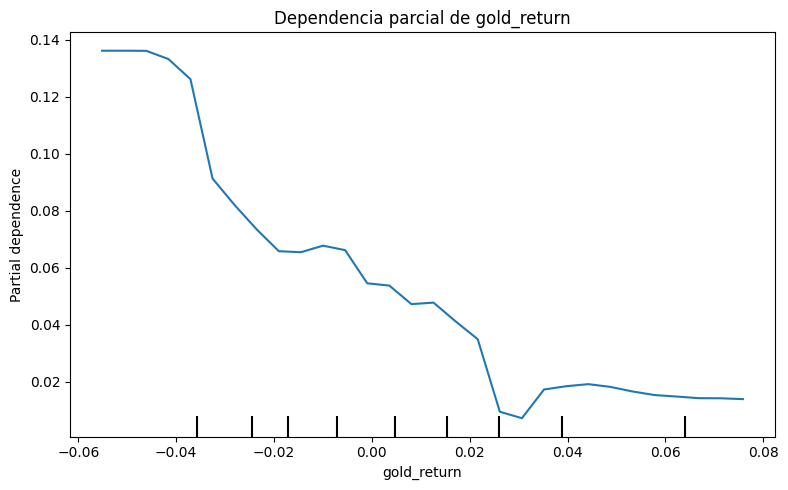

/usr/local/lib/python3.12/dist-packages/sklearn/inspection/_plot/partial_dependence.py:976: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim([min_val, max_val])


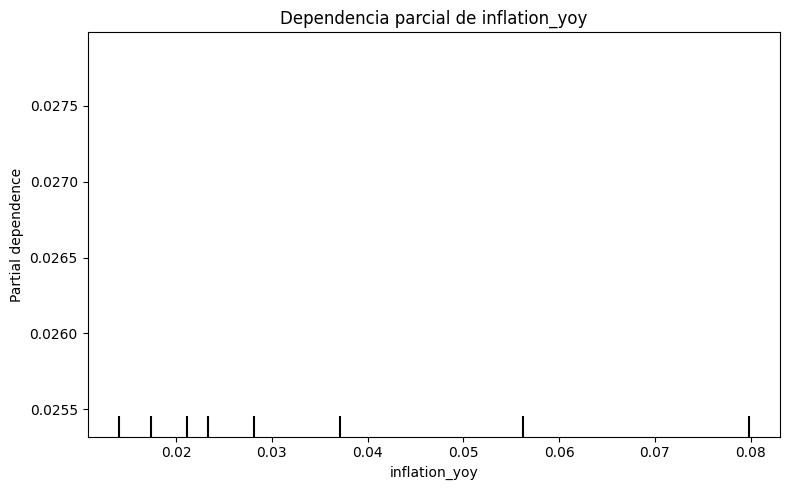

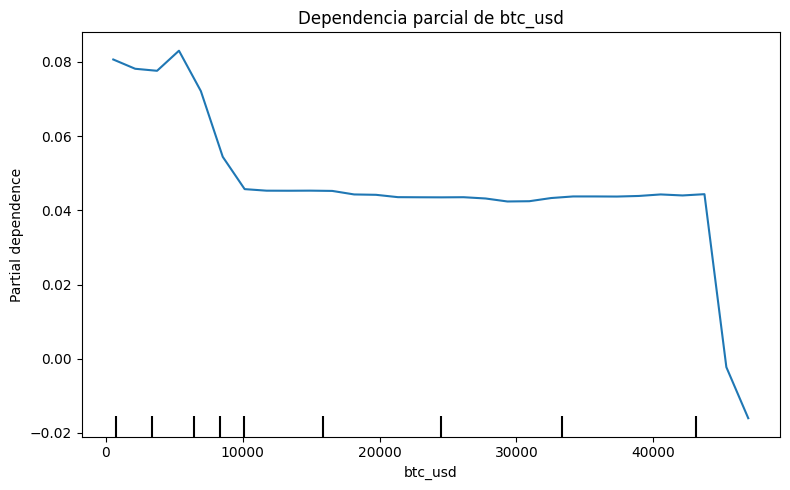

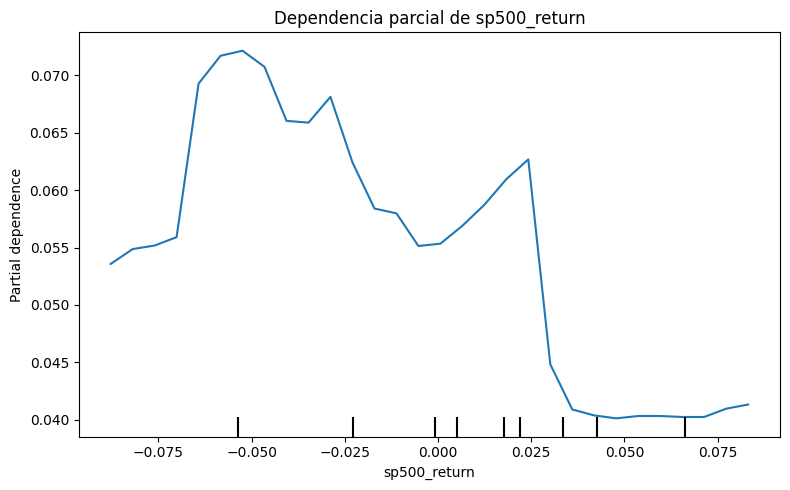


Análisis multifactorial completado.
Archivos generados:
- 07_correlaciones_moviles_btc_sp500_oro.png
- 08_correlaciones_lead_lag.png
- 09_regimen_inflacion.png
- 10_regimen_m2.png
- 11_regimen_tipos_interes.png
- 12_analisis_halvings.png
- 13_precision_direccional.png
- 14_validacion_temporal_mae.png
- 15_1_dependencia_parcial_gold_return.png
- 15_2_dependencia_parcial_inflation_yoy.png
- 15_3_dependencia_parcial_btc_usd.png
- 15_4_dependencia_parcial_sp500_return.png
- analisis_halvings.csv
- correlaciones_lead_lag.csv
- correlaciones_moviles_12m.csv
- precision_direccional.csv
- regimen_inflacion.csv
- regimen_m2.csv
- regimen_tipos_interes.csv
- resumen_correlaciones_moviles.csv
- validacion_temporal_detallada.csv
- validacion_temporal_resumen.csv


In [17]:
# ============================================================
# Relaciones dinámicas, regímenes económicos y validación
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import mannwhitneyu, kruskal


# ============================================================
# 0. COMPROBACIÓN Y CONFIGURACIÓN
# ============================================================

objetos_necesarios = [
    "df_model", "model_data", "date_col", "target_col",
    "X", "y", "linear_model", "rf_model"
]

faltantes = [nombre for nombre in objetos_necesarios if nombre not in globals()]

if faltantes:
    raise ValueError(
        "Faltan objetos creados en la celda anterior: "
        + ", ".join(faltantes)
    )

output_dir_multi = os.path.join(
    globals().get("output_dir", "outputs_analisis_dato"),
    "analisis_multifactorial"
)

os.makedirs(output_dir_multi, exist_ok=True)

print("5.4. ANÁLISIS MULTIFACTORIAL DE BITCOIN")
print("Carpeta de resultados:", output_dir_multi)


# ============================================================
# 1. FUNCIONES AUXILIARES
# ============================================================

def encontrar_columna(df, nombres_exactos, textos_parciales=None):
    """
    Busca primero nombres exactos y después coincidencias parciales.
    Devuelve None si no encuentra una columna compatible.
    """
    textos_parciales = textos_parciales or []

    for nombre in nombres_exactos:
        if nombre in df.columns:
            return nombre

    for columna in df.columns:
        columna_limpia = str(columna).lower()

        if any(texto.lower() in columna_limpia for texto in textos_parciales):
            return columna

    return None


def resumen_por_regimen(df, columna_regimen, columna_objetivo):
    """
    Resume el comportamiento de Bitcoin dentro de cada régimen.
    Las rentabilidades se expresan en porcentaje.
    """
    resumen = (
        df.dropna(subset=[columna_regimen, columna_objetivo])
        .groupby(columna_regimen)[columna_objetivo]
        .agg(
            Observaciones="count",
            Rentabilidad_media="mean",
            Rentabilidad_mediana="median",
            Volatilidad="std"
        )
        .reset_index()
    )

    porcentaje_positivo = (
        df.dropna(subset=[columna_regimen, columna_objetivo])
        .groupby(columna_regimen)[columna_objetivo]
        .apply(lambda serie: (serie > 0).mean() * 100)
        .reset_index(name="Meses_positivos_%")
    )

    resumen = resumen.merge(
        porcentaje_positivo,
        on=columna_regimen,
        how="left"
    )

    resumen["Rentabilidad_media_%"] = resumen["Rentabilidad_media"] * 100
    resumen["Rentabilidad_mediana_%"] = resumen["Rentabilidad_mediana"] * 100
    resumen["Volatilidad_%"] = resumen["Volatilidad"] * 100

    return resumen[
        [
            columna_regimen,
            "Observaciones",
            "Rentabilidad_media_%",
            "Rentabilidad_mediana_%",
            "Volatilidad_%",
            "Meses_positivos_%"
        ]
    ]


def guardar_grafico(nombre):
    """
    Guarda el gráfico actual con calidad suficiente para el TFG.
    """
    ruta = os.path.join(output_dir_multi, nombre)
    plt.tight_layout()
    plt.savefig(ruta, dpi=300, bbox_inches="tight")
    plt.show()


def precision_direccional(y_real, y_predicho):
    """
    Porcentaje de observaciones en las que se acierta
    el signo de la rentabilidad.
    """
    y_real = np.asarray(y_real)
    y_predicho = np.asarray(y_predicho)

    mascara = y_real != 0

    if mascara.sum() == 0:
        return np.nan

    return (
        np.sign(y_real[mascara]) == np.sign(y_predicho[mascara])
    ).mean() * 100


# ============================================================
# 2. IDENTIFICACIÓN DE VARIABLES
# ============================================================

col_sp500_return = encontrar_columna(
    df_model,
    ["sp500_return", "sp500_returns"],
    ["sp500_return", "s&p500_return"]
)

col_gold_return = encontrar_columna(
    df_model,
    ["gold_return", "gold_returns"],
    ["gold_return", "oro_return", "rentabilidad_oro"]
)

col_inflation = encontrar_columna(
    df_model,
    ["inflation_yoy"],
    ["inflation_yoy", "inflacion_interanual"]
)

col_m2_growth = encontrar_columna(
    df_model,
    ["m2_growth_yoy"],
    ["m2_growth", "crecimiento_m2"]
)

col_fed_rate = encontrar_columna(
    df_model,
    ["fed_funds_rate"],
    ["fed_funds_rate", "interest_rate", "tipo_interes"]
)

col_fed_change = encontrar_columna(
    df_model,
    ["fed_funds_change"],
    ["fed_funds_change", "rate_change", "cambio_tipo"]
)

col_btc_volatility = encontrar_columna(
    df_model,
    ["btc_volatility_3m"],
    ["btc_volatility", "volatilidad_btc"]
)

col_halving = encontrar_columna(
    df_model,
    ["halving_window_3m"],
    ["halving"]
)

columnas_detectadas = pd.DataFrame({
    "Concepto": [
        "Rentabilidad S&P 500",
        "Rentabilidad del oro",
        "Inflación interanual",
        "Crecimiento M2",
        "Tipo de interés",
        "Cambio en tipos",
        "Volatilidad Bitcoin",
        "Ventana halving"
    ],
    "Columna_detectada": [
        col_sp500_return,
        col_gold_return,
        col_inflation,
        col_m2_growth,
        col_fed_rate,
        col_fed_change,
        col_btc_volatility,
        col_halving
    ]
})

print("\nVariables detectadas:")
display(columnas_detectadas)


# ============================================================
# 3. CORRELACIONES MÓVILES: BITCOIN, S&P 500 Y ORO
# ============================================================

columnas_relacion = [date_col, target_col]

if col_sp500_return:
    columnas_relacion.append(col_sp500_return)

if col_gold_return:
    columnas_relacion.append(col_gold_return)

df_relaciones = (
    df_model[columnas_relacion]
    .copy()
    .sort_values(date_col)
)

# Ventana móvil de 12 meses
if col_sp500_return:
    df_relaciones["Corr_BTC_SP500_12m"] = (
        df_relaciones[target_col]
        .rolling(window=12, min_periods=8)
        .corr(df_relaciones[col_sp500_return])
    )

if col_gold_return:
    df_relaciones["Corr_BTC_Oro_12m"] = (
        df_relaciones[target_col]
        .rolling(window=12, min_periods=8)
        .corr(df_relaciones[col_gold_return])
    )

columnas_corr = [
    col for col in ["Corr_BTC_SP500_12m", "Corr_BTC_Oro_12m"]
    if col in df_relaciones.columns
]

if columnas_corr:
    resumen_correlaciones = df_relaciones[columnas_corr].agg(
        ["mean", "median", "min", "max"]
    ).T.reset_index()

    resumen_correlaciones.columns = [
        "Relación", "Media", "Mediana", "Mínimo", "Máximo"
    ]

    print("\nResumen de correlaciones móviles:")
    display(resumen_correlaciones)

    resumen_correlaciones.to_csv(
        os.path.join(output_dir_multi, "resumen_correlaciones_moviles.csv"),
        index=False
    )

    df_relaciones.to_csv(
        os.path.join(output_dir_multi, "correlaciones_moviles_12m.csv"),
        index=False
    )

    plt.figure(figsize=(12, 6))
    plt.axhline(0, linewidth=1)

    if "Corr_BTC_SP500_12m" in df_relaciones.columns:
        plt.plot(
            df_relaciones[date_col],
            df_relaciones["Corr_BTC_SP500_12m"],
            label="Bitcoin y S&P 500"
        )

    if "Corr_BTC_Oro_12m" in df_relaciones.columns:
        plt.plot(
            df_relaciones[date_col],
            df_relaciones["Corr_BTC_Oro_12m"],
            label="Bitcoin y oro"
        )

    plt.title("Evolución de la correlación móvil de Bitcoin")
    plt.xlabel("Fecha")
    plt.ylabel("Correlación móvil de 12 meses")
    plt.ylim(-1, 1)
    plt.legend()
    plt.grid(alpha=0.3)

    guardar_grafico("07_correlaciones_moviles_btc_sp500_oro.png")

else:
    print("\nNo se han encontrado columnas suficientes para calcular correlaciones móviles.")


# ============================================================
# 4. ANÁLISIS LEAD-LAG: ¿QUÉ MERCADO SE MUEVE ANTES?
# ============================================================

resultados_lags = []

# Lag positivo:
# la variable financiera pertenece a meses anteriores a la rentabilidad actual de Bitcoin.
for lag in range(-6, 7):

    fila = {"Lag_meses": lag}

    if col_sp500_return:
        fila["Corr_BTC_SP500"] = df_model[target_col].corr(
            df_model[col_sp500_return].shift(lag)
        )

    if col_gold_return:
        fila["Corr_BTC_Oro"] = df_model[target_col].corr(
            df_model[col_gold_return].shift(lag)
        )

    resultados_lags.append(fila)

lead_lag_df = pd.DataFrame(resultados_lags)

print("\nCorrelaciones adelantadas y rezagadas:")
display(lead_lag_df)

lead_lag_df.to_csv(
    os.path.join(output_dir_multi, "correlaciones_lead_lag.csv"),
    index=False
)

plt.figure(figsize=(11, 6))
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1, linestyle="--")

if "Corr_BTC_SP500" in lead_lag_df.columns:
    plt.plot(
        lead_lag_df["Lag_meses"],
        lead_lag_df["Corr_BTC_SP500"],
        marker="o",
        label="S&P 500"
    )

if "Corr_BTC_Oro" in lead_lag_df.columns:
    plt.plot(
        lead_lag_df["Lag_meses"],
        lead_lag_df["Corr_BTC_Oro"],
        marker="o",
        label="Oro"
    )

plt.title("Relación adelantada y rezagada con la rentabilidad de Bitcoin")
plt.xlabel("Rezago de la variable financiera (meses)")
plt.ylabel("Correlación")
plt.xticks(range(-6, 7))
plt.legend()
plt.grid(alpha=0.3)

guardar_grafico("08_correlaciones_lead_lag.png")


# ============================================================
# 5. REGÍMENES DE INFLACIÓN
# ============================================================

# model_data contiene las variables explicativas desplazadas un mes,
# tal como se utilizaron en los modelos.
if col_inflation and col_inflation in model_data.columns:

    df_inflacion = model_data[
        [date_col, target_col, col_inflation]
    ].dropna().copy()

    mediana_inflacion = df_inflacion[col_inflation].median()

    df_inflacion["Regimen_inflacion"] = np.where(
        df_inflacion[col_inflation] >= mediana_inflacion,
        "Inflación alta",
        "Inflación baja"
    )

    tabla_inflacion = resumen_por_regimen(
        df_inflacion,
        "Regimen_inflacion",
        target_col
    )

    print("\nBitcoin según régimen de inflación:")
    display(tabla_inflacion)

    tabla_inflacion.to_csv(
        os.path.join(output_dir_multi, "regimen_inflacion.csv"),
        index=False
    )

    plt.figure(figsize=(8, 5))
    plt.bar(
        tabla_inflacion["Regimen_inflacion"],
        tabla_inflacion["Rentabilidad_media_%"]
    )
    plt.axhline(0, linewidth=1)
    plt.title("Rentabilidad media de Bitcoin según el nivel de inflación")
    plt.ylabel("Rentabilidad media mensual (%)")
    plt.xlabel("")
    plt.grid(axis="y", alpha=0.3)

    guardar_grafico("09_regimen_inflacion.png")

    grupo_bajo = df_inflacion.loc[
        df_inflacion["Regimen_inflacion"] == "Inflación baja",
        target_col
    ]

    grupo_alto = df_inflacion.loc[
        df_inflacion["Regimen_inflacion"] == "Inflación alta",
        target_col
    ]

    if len(grupo_bajo) >= 5 and len(grupo_alto) >= 5:
        estadistico, p_valor = mannwhitneyu(
            grupo_bajo,
            grupo_alto,
            alternative="two-sided"
        )

        print(
            "Prueba Mann-Whitney inflación:",
            f"estadístico={estadistico:.3f}, p-valor={p_valor:.4f}"
        )


# ============================================================
# 6. REGÍMENES DE LIQUIDEZ: CRECIMIENTO DE M2
# ============================================================

if col_m2_growth and col_m2_growth in model_data.columns:

    df_m2 = model_data[
        [date_col, target_col, col_m2_growth]
    ].dropna().copy()

    # Si hay suficientes periodos negativos, diferenciamos expansión y contracción.
    negativos = (df_m2[col_m2_growth] < 0).sum()
    positivos = (df_m2[col_m2_growth] >= 0).sum()

    if negativos >= 5 and positivos >= 5:
        df_m2["Regimen_M2"] = np.where(
            df_m2[col_m2_growth] >= 0,
            "Expansión de M2",
            "Contracción de M2"
        )
    else:
        mediana_m2 = df_m2[col_m2_growth].median()

        df_m2["Regimen_M2"] = np.where(
            df_m2[col_m2_growth] >= mediana_m2,
            "Crecimiento alto de M2",
            "Crecimiento bajo de M2"
        )

    tabla_m2 = resumen_por_regimen(
        df_m2,
        "Regimen_M2",
        target_col
    )

    print("\nBitcoin según régimen de liquidez:")
    display(tabla_m2)

    tabla_m2.to_csv(
        os.path.join(output_dir_multi, "regimen_m2.csv"),
        index=False
    )

    plt.figure(figsize=(8, 5))
    plt.bar(
        tabla_m2["Regimen_M2"],
        tabla_m2["Rentabilidad_media_%"]
    )
    plt.axhline(0, linewidth=1)
    plt.title("Rentabilidad media de Bitcoin según el crecimiento de M2")
    plt.ylabel("Rentabilidad media mensual (%)")
    plt.xlabel("")
    plt.xticks(rotation=10)
    plt.grid(axis="y", alpha=0.3)

    guardar_grafico("10_regimen_m2.png")

    grupos_m2 = [
        grupo[target_col].values
        for _, grupo in df_m2.groupby("Regimen_M2")
        if len(grupo) >= 5
    ]

    if len(grupos_m2) == 2:
        estadistico, p_valor = mannwhitneyu(
            grupos_m2[0],
            grupos_m2[1],
            alternative="two-sided"
        )

        print(
            "Prueba Mann-Whitney M2:",
            f"estadístico={estadistico:.3f}, p-valor={p_valor:.4f}"
        )


# ============================================================
# 7. REGÍMENES DE TIPOS DE INTERÉS
# ============================================================

if col_fed_change and col_fed_change in model_data.columns:
    columna_cambio_tipos = col_fed_change

elif col_fed_rate and col_fed_rate in model_data.columns:
    model_data = model_data.copy()
    model_data["cambio_tipos_calculado"] = model_data[col_fed_rate].diff()
    columna_cambio_tipos = "cambio_tipos_calculado"

else:
    columna_cambio_tipos = None


if columna_cambio_tipos:

    df_tipos = model_data[
        [date_col, target_col, columna_cambio_tipos]
    ].dropna().copy()

    tolerancia = 1e-8

    condiciones = [
        df_tipos[columna_cambio_tipos] > tolerancia,
        df_tipos[columna_cambio_tipos] < -tolerancia
    ]

    categorias = [
        "Subida de tipos",
        "Bajada de tipos"
    ]

    df_tipos["Regimen_tipos"] = np.select(
        condiciones,
        categorias,
        default="Tipos sin cambio"
    )

    tabla_tipos = resumen_por_regimen(
        df_tipos,
        "Regimen_tipos",
        target_col
    )

    orden_tipos = [
        "Bajada de tipos",
        "Tipos sin cambio",
        "Subida de tipos"
    ]

    tabla_tipos["orden"] = tabla_tipos["Regimen_tipos"].map(
        {nombre: i for i, nombre in enumerate(orden_tipos)}
    )

    tabla_tipos = (
        tabla_tipos
        .sort_values("orden")
        .drop(columns="orden")
    )

    print("\nBitcoin según movimiento de los tipos de interés:")
    display(tabla_tipos)

    tabla_tipos.to_csv(
        os.path.join(output_dir_multi, "regimen_tipos_interes.csv"),
        index=False
    )

    plt.figure(figsize=(9, 5))
    plt.bar(
        tabla_tipos["Regimen_tipos"],
        tabla_tipos["Rentabilidad_media_%"]
    )
    plt.axhline(0, linewidth=1)
    plt.title("Rentabilidad media de Bitcoin según el movimiento de los tipos")
    plt.ylabel("Rentabilidad media mensual (%)")
    plt.xlabel("")
    plt.grid(axis="y", alpha=0.3)

    guardar_grafico("11_regimen_tipos_interes.png")

    grupos_tipos = [
        grupo[target_col].values
        for _, grupo in df_tipos.groupby("Regimen_tipos")
        if len(grupo) >= 5
    ]

    if len(grupos_tipos) >= 2:
        estadistico, p_valor = kruskal(*grupos_tipos)

        print(
            "Prueba Kruskal-Wallis tipos:",
            f"estadístico={estadistico:.3f}, p-valor={p_valor:.4f}"
        )


# ============================================================
# 8. COMPORTAMIENTO EN TORNO A LOS HALVINGS
# ============================================================

df_halving = df_model[[date_col, target_col]].dropna().copy()
df_halving[date_col] = pd.to_datetime(df_halving[date_col])

fechas_halving = pd.to_datetime([
    "2012-11-28",
    "2016-07-09",
    "2020-05-11",
    "2024-04-20"
])


def distancia_meses(fecha, evento):
    return (
        (fecha.year - evento.year) * 12
        + fecha.month
        - evento.month
    )


def clasificar_periodo_halving(fecha):
    """
    Clasifica cada mes respecto al halving más cercano.
    """
    distancias = [
        distancia_meses(fecha, evento)
        for evento in fechas_halving
    ]

    distancia_cercana = min(
        distancias,
        key=lambda x: abs(x)
    )

    if -3 <= distancia_cercana <= -1:
        return "3 meses anteriores"

    if 0 <= distancia_cercana <= 3:
        return "0-3 meses posteriores"

    if 4 <= distancia_cercana <= 12:
        return "4-12 meses posteriores"

    return "Fuera de ventana"


df_halving["Periodo_halving"] = df_halving[date_col].apply(
    clasificar_periodo_halving
)

tabla_halving = resumen_por_regimen(
    df_halving,
    "Periodo_halving",
    target_col
)

orden_halving = [
    "3 meses anteriores",
    "0-3 meses posteriores",
    "4-12 meses posteriores",
    "Fuera de ventana"
]

tabla_halving["orden"] = tabla_halving["Periodo_halving"].map(
    {nombre: i for i, nombre in enumerate(orden_halving)}
)

tabla_halving = (
    tabla_halving
    .sort_values("orden")
    .drop(columns="orden")
)

print("\nComportamiento de Bitcoin en torno a los halvings:")
display(tabla_halving)

tabla_halving.to_csv(
    os.path.join(output_dir_multi, "analisis_halvings.csv"),
    index=False
)

plt.figure(figsize=(10, 5))
plt.bar(
    tabla_halving["Periodo_halving"],
    tabla_halving["Rentabilidad_media_%"]
)
plt.axhline(0, linewidth=1)
plt.title("Rentabilidad media de Bitcoin en torno a los halvings")
plt.ylabel("Rentabilidad media mensual (%)")
plt.xlabel("")
plt.xticks(rotation=12)
plt.grid(axis="y", alpha=0.3)

guardar_grafico("12_analisis_halvings.png")

grupos_halving = [
    grupo[target_col].values
    for _, grupo in df_halving.groupby("Periodo_halving")
    if len(grupo) >= 5
]

if len(grupos_halving) >= 2:
    estadistico, p_valor = kruskal(*grupos_halving)

    print(
        "Prueba Kruskal-Wallis halvings:",
        f"estadístico={estadistico:.3f}, p-valor={p_valor:.4f}"
    )


# ============================================================
# 9. PRECISIÓN DIRECCIONAL DE LOS MODELOS
# ============================================================

if all(
    nombre in globals()
    for nombre in ["y_test", "y_pred_linear", "y_pred_rf"]
):

    precision_lineal = precision_direccional(
        y_test,
        y_pred_linear
    )

    precision_rf = precision_direccional(
        y_test,
        y_pred_rf
    )

    # Baseline: predecir siempre la dirección mayoritaria del entrenamiento.
    signo_mayoritario = 1 if (y_train > 0).mean() >= 0.5 else -1

    prediccion_baseline = np.full(
        shape=len(y_test),
        fill_value=signo_mayoritario
    )

    precision_baseline = precision_direccional(
        y_test,
        prediccion_baseline
    )

    tabla_direccion = pd.DataFrame({
        "Modelo": [
            "Baseline dirección mayoritaria",
            "Regresión lineal múltiple",
            "Random Forest Regressor"
        ],
        "Precision_direccional_%": [
            precision_baseline,
            precision_lineal,
            precision_rf
        ]
    })

    print("\nPrecisión direccional:")
    display(tabla_direccion)

    tabla_direccion.to_csv(
        os.path.join(output_dir_multi, "precision_direccional.csv"),
        index=False
    )

    plt.figure(figsize=(9, 5))
    plt.bar(
        tabla_direccion["Modelo"],
        tabla_direccion["Precision_direccional_%"]
    )
    plt.axhline(50, linewidth=1, linestyle="--")
    plt.title("Capacidad para anticipar la dirección de Bitcoin")
    plt.ylabel("Meses con dirección correctamente predicha (%)")
    plt.xlabel("")
    plt.xticks(rotation=8)
    plt.grid(axis="y", alpha=0.3)

    guardar_grafico("13_precision_direccional.png")


# ============================================================
# 10. VALIDACIÓN TEMPORAL CON VENTANAS SUCESIVAS
# ============================================================

numero_splits = 5 if len(X) >= 60 else 3
tscv = TimeSeriesSplit(n_splits=numero_splits)

resultados_validacion = []

for fold, (indices_train, indices_test) in enumerate(
    tscv.split(X),
    start=1
):

    X_train_fold = X.iloc[indices_train]
    X_test_fold = X.iloc[indices_test]

    y_train_fold = y.iloc[indices_train]
    y_test_fold = y.iloc[indices_test]

    modelo_lineal_fold = clone(linear_model)
    modelo_rf_fold = clone(rf_model)

    modelo_lineal_fold.fit(
        X_train_fold,
        y_train_fold
    )

    modelo_rf_fold.fit(
        X_train_fold,
        y_train_fold
    )

    pred_lineal_fold = modelo_lineal_fold.predict(
        X_test_fold
    )

    pred_rf_fold = modelo_rf_fold.predict(
        X_test_fold
    )

    for nombre_modelo, predicciones in [
        ("Regresión lineal", pred_lineal_fold),
        ("Random Forest", pred_rf_fold)
    ]:

        resultados_validacion.append({
            "Ventana": fold,
            "Modelo": nombre_modelo,
            "Fecha_inicio_test": model_data.iloc[
                indices_test
            ][date_col].min(),
            "Fecha_fin_test": model_data.iloc[
                indices_test
            ][date_col].max(),
            "MAE": mean_absolute_error(
                y_test_fold,
                predicciones
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    y_test_fold,
                    predicciones
                )
            ),
            "R2": r2_score(
                y_test_fold,
                predicciones
            ),
            "Precision_direccional_%": precision_direccional(
                y_test_fold,
                predicciones
            )
        })

validacion_df = pd.DataFrame(resultados_validacion)

print("\nValidación temporal por ventanas:")
display(validacion_df)

resumen_validacion = (
    validacion_df
    .groupby("Modelo")
    .agg(
        MAE_medio=("MAE", "mean"),
        RMSE_medio=("RMSE", "mean"),
        R2_medio=("R2", "mean"),
        Precision_direccional_media=(
            "Precision_direccional_%",
            "mean"
        )
    )
    .reset_index()
)

print("\nResumen de validación temporal:")
display(resumen_validacion)

validacion_df.to_csv(
    os.path.join(output_dir_multi, "validacion_temporal_detallada.csv"),
    index=False
)

resumen_validacion.to_csv(
    os.path.join(output_dir_multi, "validacion_temporal_resumen.csv"),
    index=False
)

plt.figure(figsize=(10, 5))

for nombre_modelo, grupo in validacion_df.groupby("Modelo"):
    plt.plot(
        grupo["Ventana"],
        grupo["MAE"],
        marker="o",
        label=nombre_modelo
    )

plt.title("Evolución del MAE en la validación temporal")
plt.xlabel("Ventana temporal")
plt.ylabel("MAE")
plt.xticks(range(1, numero_splits + 1))
plt.legend()
plt.grid(alpha=0.3)

guardar_grafico("14_validacion_temporal_mae.png")


# ============================================================
# 11. DEPENDENCIA PARCIAL DEL RANDOM FOREST
# ============================================================

# Seleccionamos las cuatro variables más importantes del modelo
# que estén disponibles en X_train.
if "importance_df" in globals():

    variables_pd = [
        variable
        for variable in importance_df["Variable"].head(6)
        if variable in X_train.columns
    ][:4]

else:
    variables_pd = list(X_train.columns[:4])


print("\nVariables seleccionadas para dependencia parcial:")
print(variables_pd)

for posicion, variable in enumerate(variables_pd, start=1):

    try:
        fig, ax = plt.subplots(figsize=(8, 5))

        PartialDependenceDisplay.from_estimator(
            rf_model,
            X_train,
            features=[variable],
            kind="average",
            grid_resolution=30,
            ax=ax
        )

        ax.set_title(
            f"Dependencia parcial de {variable}"
        )

        plt.tight_layout()
        plt.savefig(
            os.path.join(
                output_dir_multi,
                f"15_{posicion}_dependencia_parcial_{variable}.png"
            ),
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()

    except Exception as error:
        print(
            f"No se pudo generar la dependencia parcial de {variable}:",
            error
        )


# ============================================================
# 12. RESUMEN DE ARCHIVOS GENERADOS
# ============================================================

print("\nAnálisis multifactorial completado.")
print("Archivos generados:")

for archivo in sorted(os.listdir(output_dir_multi)):
    print("-", archivo)